## Step 1: 3D Data Pipeline & MONAI Transforms

In [58]:
import os 
import torch

# [CONFIG]
KL_DIVERGENCE = '../../data/baseline/kl_divergence_beta_5.00e-05.csv'
CHECKPOINT_PATH = '../../models/checkpoints/beta_5.00e-05_best.pth'
MASK_PATH = '../../data/masks/rmask_ICV.nii'
IMAGES_ROOT     = '../../data/raw/ppmi_images'  # parent folder of PD/Cont/SWEDD
OUTPUT_DIR      = '../../results/augmentation/'
FIGURES_DIR     = '../../results/figures/'
os.makedirs(OUTPUT_DIR,  exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

N_SUBJECTS   = 100
RANDOM_STATE = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Device: {DEVICE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Images root: {IMAGES_ROOT}")

Device: cpu
Checkpoint: ../../models/checkpoints/beta_5.00e-05_best.pth
Images root: ../../data/raw/ppmi_images


In [ ]:
import os
import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import monai.transforms as mt


class ParkinsonSPECTDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        file_path = row['dcm_path']
        
        # 1. Load your actual medical image file
        image_np = self.loader(file_path) # e.g., shape could be [109, 64, 128] or similar
        
        # 2. Ensure it is a numpy array and add a channel dimension if it doesn't have one
        if isinstance(image_np, torch.Tensor):
            image_np = image_np.numpy()
            
        if image_np.ndim == 3:
            # Shape is [Depth, Height, Width] -> Add channel to make it [1, Depth, Height, Width]
            image_np = np.expand_dims(image_np, axis=0)
        
        data_dict = {'image': image_np}
        
        if self.transform:
            data_dict = self.transform(data_dict)
            
        return {
            'image': data_dict['image'], # Will be tensor of shape [1, 64, 128, 128]
            'label': row['label'], 
            'patno': row['PATNO']
        }

# Using the correct dictionary transforms (with 'd' at the end)
train_transforms = mt.Compose([
    mt.Spacingd(keys=['image'], pixdim=(1.5, 1.5, 1.5), mode='bilinear'),
    mt.ScaleIntensityd(keys=['image']),
    mt.Resized(keys=['image'], spatial_size=(64, 128, 128)),
    mt.ToTensord(keys=['image'])
])

## Step 2: 3D $\beta$-VAE Architecture & Wrapper

In [49]:
import torch
import torch.nn as nn

class CustomEncoder(nn.Module):
    def __init__ (self, latent_dim=256):
        super().__init__()
        # 3D Convolutional layers to downsample the volume
        self.conv_net = nn.Sequential(
            nn.Conv3d(1, 32, kernel_size=4, stride=2, padding=1),  # [B, 32, 32, 64, 64]
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.Conv3d(32, 64, kernel_size=4, stride=2, padding=1), # [B, 64, 16, 32, 32]
            nn.BatchNorm3d(64),
            nn.ReLU(),
            nn.Conv3d(64, 128, kernel_size=4, stride=2, padding=1),# [B, 128, 8, 16, 16]
            nn.BatchNorm3d(128),
            nn.ReLU(),
            nn.Conv3d(128, 256, kernel_size=4, stride=2, padding=1),# [B, 256, 4, 8, 8]
            nn.BatchNorm3d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool3d((1, 1, 1)) # Global pooling to collapse spatial dimensions
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_var = nn.Linear(256, latent_dim)

    def forward(self, x):
        h = self.conv_net(x)
        h = torch.flatten(h, start_dim=1)
        mu = self.fc_mu(h)
        log_var = self.fc_var(h)
        return mu, log_var


class ComplexBottleneckDeconvDecoder(nn.Module):
    def __init__(self, latent_dim=256):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 256 * 4 * 8 * 8) # Expand back to bottleneck shape
        
        # 3D Transpose Convolutions to upsample back to [1, 64, 128, 128]
        self.deconv_net = nn.Sequential(
            nn.ConvTranspose3d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(),
            nn.ConvTranspose3d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(),
            nn.ConvTranspose3d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(),
            nn.ConvTranspose3d(32, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid() # Outputs values between 0 and 1
        )

    def forward(self, z):
        h = self.fc(z)
        h = h.view(-1, 256, 4, 8, 8) # Reshape to match bottleneck tensor dimensions
        recon = self.deconv_net(h)
        return recon


class VAEWrapper(nn.Module):
    """
    Wrapper handling reparameterization during training and 
    deterministic mean extraction during inference.
    """
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def encode(self, x):
        mu, log_var = self.encoder(x)
        return mu # Return deterministic mean for latent space analysis

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterize(mu, log_var)
        recon = self.decoder(z)
        return recon, mu, log_var

## Step 3: The $\beta$-VAE Loss Function & Training Loop

In [50]:
import torch
import torch.nn.functional as F

def vae_loss_function(recon_x, x, mu, log_var, beta=1.0):
    """
    Computes the VAE loss: Reconstruction Loss (MSE) + beta * KL Divergence.
    """
    # 1. Reconstruction Loss: measures how closely the reconstructed scan matches the input
    recon_loss = F.mse_loss(recon_x, x, reduction='sum')
    
    # 2. KL Divergence: regularizes the latent space toward a standard normal distribution N(0, I)
    # Formula: -0.5 * sum(1 + log_var - mu^2 - exp(log_var))
    kld_loss = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    
    # Total loss weighted by the beta hyperparameter
    total_loss = recon_loss + (beta * kld_loss)
    return total_loss, recon_loss, kld_loss


def train_vae(model, dataloader, optimizer, device, beta=1.0, epochs=2):
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0.0
        for batch in dataloader:  # Fixed variable name here
            images = batch['image'].to(device)
            optimizer.zero_grad()
            
            recon_images, mu, log_var = model(images)
            loss, _, _ = vae_loss_function(recon_images, images, mu, log_var, beta=beta)
            
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            
        print(f"Epoch [{epoch+1}/{epochs}] Completed. Total Loss: {epoch_loss:.4f}")

# --- Example Initialization to run the training ---
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# encoder = CustomEncoder(latent_dim=256)
# decoder = ComplexBottleneckDeconvDecoder(latent_dim=256)
# model = VAEWrapper(encoder, decoder).to(device)
# optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

## Step 4: Extracting Latent Vectors & Saving to CSV

In [51]:
import torch
import pandas as pd
from tqdm import tqdm

def extract_latent_features(model, dataloader, device, output_csv_path):
    """
    Passes all scans through the trained VAE model's encoder 
    to extract deterministic latent representations (mu) and saves them to a CSV.
    """
    model.eval()
    results = []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Extracting Latent Representations"):
            images = batch['image'].to(device)
            patnos = batch['patno']
            labels = batch['label']

            # Extract deterministic mean (mu) using the encode method
            mu = model.encode(images) # Shape: [Batch_Size, latent_dim]
            mu_cpu = mu.cpu().numpy()

            for i in range(len(patnos)):
                row_data = {
                    'PATNO': patnos[i].item() if hasattr(patnos[i], 'item') else patnos[i],
                    'label': labels[i]
                }
                
                # Dynamically assign each dimension of the latent vector as a column
                latent_vector = mu_cpu[i]
                for dim_idx, val in enumerate(latent_vector):
                    row_data[f'latent_{dim_idx}'] = val
                
                results.append(row_data)

    # Convert results into a Pandas DataFrame and save to CSV
    df_latent = pd.DataFrame(results)
    df_latent.to_csv(output_csv_path, index=False)
    print(f"Latent features successfully saved to {output_csv_path} (Total rows: {len(df_latent)})")
    return df_latent

# --- Example Usage ---
# latent_df = extract_latent_features(model, val_dataloader, device, 'final_validation_vae_data.csv')

## Step 5: Image Reconstruction & Visualization Script

In [52]:
import torch
import matplotlib.pyplot as plt

def visualize_reconstruction(model, dataloader, device, slice_idx=32):
    """
    Picks a sample batch from the dataloader, passes it through the VAE,
    and plots original vs. reconstructed 3D brain scans side-by-side.
    """
    model.eval()
    
    # Fetch a single batch
    batch = next(iter(dataloader))
    images = batch['image'].to(device)
    
    with torch.no_grad():
        # Forward pass: get reconstruction
        recon_images, _, _ = model(images)
        
    # Move tensors to CPU for plotting
    original = images[0].cpu().numpy()  # Shape: [C, D, H, W] -> [1, 64, 128, 128]
    reconstructed = recon_images[0].cpu().numpy()
    
    # Select a specific depth slice (e.g., middle of the 3D volume)
    orig_slice = original[0, slice_idx, :, :]
    recon_slice = reconstructed[0, slice_idx, :, :]
    
    # Plotting side-by-side comparison
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    axes[0].imshow(orig_slice, cmap='gray')
    axes[0].set_title("Original DaTSCAN Slice")
    axes[0].axis('off')
    
    axes[1].imshow(recon_slice, cmap='gray')
    axes[1].set_title("Reconstructed DaTSCAN Slice")
    axes[1].axis('off')
    
    plt.suptitle(f"VAE Image Reconstruction Check (Slice Depth: {slice_idx})", fontsize=14)
    plt.tight_layout()
    plt.show()

# --- Example Usage ---
# visualize_reconstruction(model, val_dataloader, device, slice_idx=32)

## Step 7: Run the Encode and Decoder

In [53]:
from pathlib import Path
import numpy as np


# [LOAD-IMAGES]

IMAGE_ROOT = Path('../../data/raw/ppmi_images')
GROUPS = {
    'PD':    IMAGE_ROOT / 'PPMI_Images_PD',
    'HC':    IMAGE_ROOT / 'PPMI_Images_Cont',
    'SWEDD': IMAGE_ROOT / 'PPMI_Images_SWEDD'
}

def find_dcm_files(root_dir, label):
    """Recursively find all .dcm files and extract PATNO."""
    records = []
    for dcm_path in Path(root_dir).rglob('*.dcm'):
        parts = dcm_path.parts
        # PATNO is the first subfolder under the group root
        relative = dcm_path.relative_to(root_dir)
        patno = relative.parts[0]
        records.append({
            'PATNO':    patno,
            'label':    label,
            'dcm_path': str(dcm_path)
        })
    return records

print("Scanning image folders...")
records = []
for label, folder in GROUPS.items():
    found = find_dcm_files(folder, label)
    print(f"  {label}: {len(found)} scans found")

    records.extend(found)
print("Records", records)
df_images = pd.DataFrame(records)
df_images = df_images.drop_duplicates(subset=['PATNO'], keep='first')

print(f"\nTotal unique subjects: {len(df_images)}")
print(df_images['label'].value_counts().to_string())
print(f"\nSample paths:")
print(df_images['dcm_path'].head(3).to_string())

# Select 100 subjects — stratified by group
np.random.seed(RANDOM_STATE)
n_per_group = {'PD': 70, 'HC': 20, 'SWEDD': 10}
selected = []
for label, n in n_per_group.items():
    group = df_images[df_images['label'] == label]
    n = min(n, len(group))
    selected.append(group.sample(n, random_state=RANDOM_STATE))

df_selected = pd.concat(selected).reset_index(drop=True)
print(f"\nSelected {len(df_selected)} subjects:")
print(df_selected['label'].value_counts().to_string())

Scanning image folders...
  PD: 1222 scans found
  HC: 378 scans found
  SWEDD: 136 scans found
Records [{'PATNO': '172854', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/172854/Reconstructed_DaTSCAN/2022-09-30_12_51_28.0/I1632125/PPMI_172854_NM_Reconstructed_DaTSCAN_Br_20221019121702557_1_S1167989_I1632125.dcm'}, {'PATNO': '174996', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/174996/Reconstructed_DaTSCAN/2023-04-10_12_01_34.0/I1697979/PPMI_174996_NM_Reconstructed_DaTSCAN_Br_20230508142952090_1_S1220249_I1697979.dcm'}, {'PATNO': '142631', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/142631/Reconstructed_DaTSCAN/2022-02-15_14_29_07.0/I1562666/PPMI_142631_NM_Reconstructed_DaTSCAN_Br_20220330192012701_1_S1118837_I1562666.dcm'}, {'PATNO': '137450', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/137450/Reconstructed_DaTSCAN/2022-09-13_12_53_28.0/I1644916/PPMI_137450_NM_Reconstructed_DaTSCAN_Br_

In [54]:
print(np.array(df_images['dcm_path']))

['../../data/raw/ppmi_images/PPMI_Images_PD/172854/Reconstructed_DaTSCAN/2022-09-30_12_51_28.0/I1632125/PPMI_172854_NM_Reconstructed_DaTSCAN_Br_20221019121702557_1_S1167989_I1632125.dcm'
 '../../data/raw/ppmi_images/PPMI_Images_PD/174996/Reconstructed_DaTSCAN/2023-04-10_12_01_34.0/I1697979/PPMI_174996_NM_Reconstructed_DaTSCAN_Br_20230508142952090_1_S1220249_I1697979.dcm'
 '../../data/raw/ppmi_images/PPMI_Images_PD/142631/Reconstructed_DaTSCAN/2022-02-15_14_29_07.0/I1562666/PPMI_142631_NM_Reconstructed_DaTSCAN_Br_20220330192012701_1_S1118837_I1562666.dcm'
 ...
 '../../data/raw/ppmi_images/PPMI_Images_SWEDD/3755/Reconstructed_DaTSCAN/2013-09-18_14_34_28.0/I419263/PPMI_3755_NM_Reconstructed_DaTSCAN_Br_20140408100826120_1_S215533_I419263.dcm'
 '../../data/raw/ppmi_images/PPMI_Images_SWEDD/3560/Reconstructed_DaTSCAN/2011-11-09_15_11_02.0/I339558/PPMI_3560_NM_Reconstructed_DaTSCAN_Br_20121011134949738_1_S135395_I339558.dcm'
 '../../data/raw/ppmi_images/PPMI_Images_SWEDD/3790/Reconstructed_Da

nvImageCodec is not available; skipping pydicom decoder plugin registration.


Epoch [1/10] Completed. Total Loss: 25959647.6348
Epoch [2/10] Completed. Total Loss: 10768647.9683
Epoch [3/10] Completed. Total Loss: 8442235.3723
Epoch [4/10] Completed. Total Loss: 7813610.8066
Epoch [5/10] Completed. Total Loss: 7384588.5864
Epoch [6/10] Completed. Total Loss: 7171827.3851
Epoch [7/10] Completed. Total Loss: 6886748.7196
Epoch [8/10] Completed. Total Loss: 6808594.3922
Epoch [9/10] Completed. Total Loss: 6592746.9362
Epoch [10/10] Completed. Total Loss: 6336749.1755


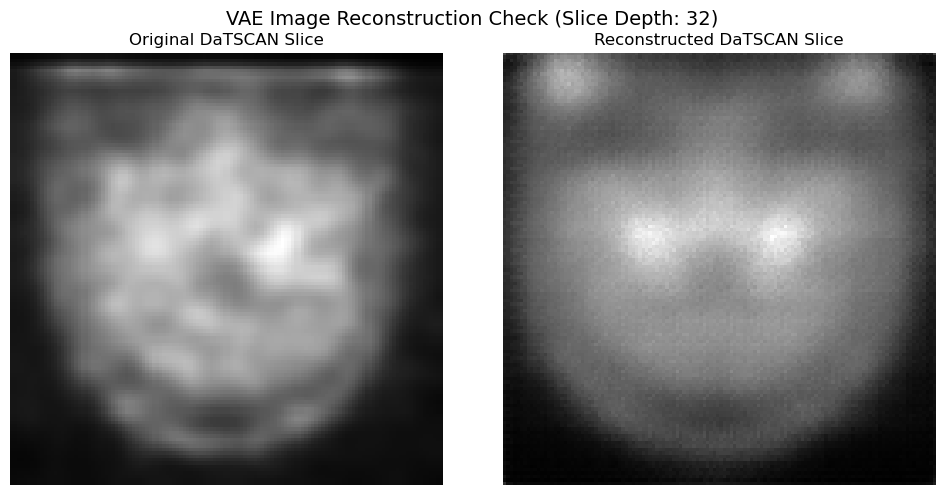

In [56]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Mock DataFrame for testing your setup
mock_df = pd.DataFrame({
    'PATNO':  np.array(df_images['PATNO']),
    'label': np.array(df_images['label']),
    'dcm_path': np.array(df_images['dcm_path'])
})

dataset = ParkinsonSPECTDataset(mock_df, transform=train_transforms)
dataloader = DataLoader(dataset, batch_size=2, shuffle=True)

# Build Model
encoder = CustomEncoder(latent_dim=256)
decoder = ComplexBottleneckDeconvDecoder(latent_dim=256)
vae_model = VAEWrapper(encoder, decoder).to(device)
optimizer = torch.optim.AdamW(vae_model.parameters(), lr=1e-4)

# Run a quick training cycle test
train_vae(vae_model, dataloader, optimizer, device, beta=1.0, epochs=10)

# Visualize reconstruction
visualize_reconstruction(vae_model, dataloader, device, slice_idx=32)

## -----------------------------------------------------------------

In [ ]:
# Check the Checkpoint
import torch
checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
encoder_keys = [k for k in checkpoint.keys() if 'encoder' in k]
for k in encoder_keys:
    print(k, checkpoint[k].shape)

In [62]:
import torch.nn as nn

# [VAE-WRAPPER]
# ─────────────────────────────────────────────────────────────────
# BottleneckAE.forward passes the full encoder output directly to
# the decoder. Since our CustomEncoder returns (mu, log_var), we
# need a wrapper that:
# 1. Extracts only mu for the decoder (deterministic inference)
# 2. Exposes an encode() method that returns mu directly
# ─────────────────────────────────────────────────────────────────

class VAEWrappers(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def encode(self, x):
        out = self.model.encoder(x)
        mu = out[0] if isinstance(out, (tuple, list)) else out
        return mu  # shape (1, 256)

    def decode(self, z):
        # conv_transpose3d needs (B, C, D, H, W) — reshape flat latent to (B, 256, 1, 1, 1)
        if z.dim() == 2:
            z = z.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1)  # → (1, 256, 1, 1, 1)
        return self.model.decoder(z)

    def forward(self, x):
        mu = self.encode(x)
        recon = self.decode(mu)
        return recon, mu

In [63]:
import sys
sys.path.append('../../models')
import importlib
import autoencoder.custom_encoder
importlib.reload(autoencoder.custom_encoder)
from autoencoder.custom_encoder import CustomEncoder
from autoencoder.selected_model import (
    BottleneckAE, ComplexBottleneckDeconvDecoder
)


def load_model(checkpoint_path, device='cpu'):
    encoder = CustomEncoder(initial_filters=32, latent_dim=256)
    decoder = ComplexBottleneckDeconvDecoder(latent_dim=256, target_shape=(64, 128, 128))
    base    = BottleneckAE(encoder, decoder)
    ckpt    = torch.load(checkpoint_path, map_location=device)
    base.load_state_dict(ckpt)
    base.eval()
    wrapped = VAEWrappers(base)
    wrapped.eval()
    # quick smoke test — catches tuple-to-decoder bug immediately
    dummy = torch.zeros(1, 1, 64, 128, 128, device=device)
    with torch.no_grad():
        recon, mu = wrapped(dummy)
    assert isinstance(recon, torch.Tensor), "decoder returned non-Tensor"
    assert isinstance(mu,    torch.Tensor), "encoder returned non-Tensor mu"
    print(f"Smoke test passed  recon {tuple(recon.shape)}  mu {tuple(mu.shape)}")
    return wrapped

model = load_model(CHECKPOINT_PATH, DEVICE)
vae = VAEWrappers(model)
vae.eval()
print("VAEWrappers ready")
print(f"Encode output dim: 256")

Smoke test passed  recon (1, 1, 64, 128, 128)  mu (1, 256)
VAEWrappers ready
Encode output dim: 256
